In [22]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm


In [23]:
twr_data_dir = r"D:\!Work\IFA\!data\Urban_fluxes_NE\raw\Moscow\LOD"

files = glob.glob (twr_data_dir + '/*full_output*.csv')
#files = glob.glob (twr_data_dir + '/*full_output*.csv')

df4site = pd.DataFrame()
for file in tqdm (files):
    cur_df = pd.read_csv (file, sep = ',', skiprows=[0,2]) #, parse_dates={'datetime':[1, 2]})
    cur_df['datetime'] = pd.to_datetime(cur_df['date'] + ' ' + cur_df['time'])
    cur_df = cur_df.set_index('datetime').replace(-9999, np.nan)
    cur_df['Tau'] = -cur_df['Tau']
    print (f'{os.path.basename(file)}: from {cur_df.index.min()} to {cur_df.index.max()}')
    
    df4site = pd.concat((df4site, cur_df))

df4site = df4site.sort_index()

df4site['Tau_from_ustar'] = df4site['air_density'] * df4site['u*']**2



 67%|██████▋   | 2/3 [00:00<00:00,  4.13it/s]

eddypro_t1_full_output_2022-11-16T131803_adv.csv: from 2022-01-01 00:30:00 to 2022-09-30 11:30:00
eddypro_t1_full_output_2023-08-01T155121_adv.csv: from 2021-05-25 20:00:00 to 2021-09-01 00:00:00


100%|██████████| 3/3 [00:00<00:00,  4.46it/s]

eddypro_t3_full_output_2023-11-09T120755_adv.csv: from 2023-06-29 16:00:00 to 2023-10-31 23:00:00


In [24]:
for c in df4site.columns:
    print(c)

filename
date
time
DOY
daytime
file_records
used_records
Tau
qc_Tau
H
qc_H
LE
qc_LE
co2_flux
qc_co2_flux
h2o_flux
qc_h2o_flux
H_strg
LE_strg
co2_strg
h2o_strg
co2_v-adv
h2o_v-adv
co2_molar_density
co2_mole_fraction
co2_mixing_ratio
co2_time_lag
co2_def_timelag
h2o_molar_density
h2o_mole_fraction
h2o_mixing_ratio
h2o_time_lag
h2o_def_timelag
sonic_temperature
air_temperature
air_pressure
air_density
air_heat_capacity
air_molar_volume
ET
water_vapor_density
e
es
specific_humidity
RH
VPD
Tdew
u_unrot
v_unrot
w_unrot
u_rot
v_rot
w_rot
wind_speed
max_wind_speed
wind_dir
yaw
pitch
roll
u*
TKE
L
(z-d)/L
bowen_ratio
T*
model
x_peak
x_offset
x_10%
x_30%
x_50%
x_70%
x_90%
un_Tau
Tau_scf
un_H
H_scf
un_LE
LE_scf
un_co2_flux
co2_scf
un_h2o_flux
h2o_scf
spikes_hf
amplitude_resolution_hf
drop_out_hf
absolute_limits_hf
skewness_kurtosis_hf
skewness_kurtosis_sf
discontinuities_hf
discontinuities_sf
timelag_hf
timelag_sf
attack_angle_hf
non_steady_wind_hf
u_spikes
v_spikes
w_spikes
ts_spikes
co2_spikes


<Axes: xlabel='datetime'>

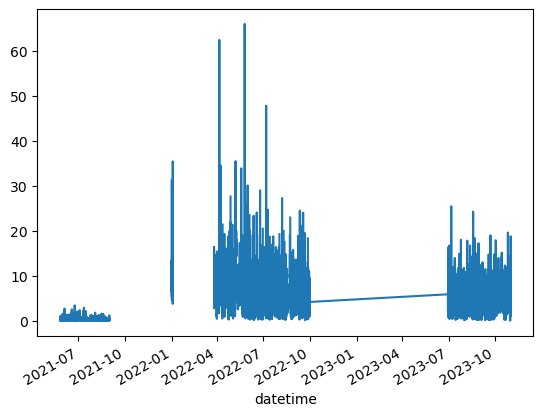

In [25]:
#df4site[['Tau', 'Tau_from_ustar']].plot()

(df4site['w_var']/df4site['u*']).plot()

In [26]:
export_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/processed/Moscow"
os.makedirs(export_dir, exist_ok=True)

df4sites = {'31m':df4site}

for level in df4sites.keys():
    df4site = df4sites[level]
    df4site['sigmaW'] = np.sqrt(df4site['w_var'])
    df2export = df4site[['H', 'Tau', 'u*', 'air_temperature', 'RH', 'air_pressure', 'air_density', 'u_unrot', 'v_unrot', 'w_unrot', 'wind_speed', 'sigmaW']]
    df2export = df2export.rename(columns = {'H': 'Qh',
                                            'Tau': 'Qtau',
                                            'u*':'Ustar', 
                                            'air_temperature': 'T_air',
                                            'RH': 'RH_air',
                                            'air_pressure': 'P_air',
                                            'air_density': 'Rho_air',
                                            'v_unrot':'Wind_V',
                                            'u_unrot':'Wind_U',
                                            'w_unrot':'Wind_W',
                                            'wind_speed':'Wind_vel', 
                                            'sigmaW':'Wind_W_std'})
    df2export.index = df2export.index
    df2export.to_csv(export_dir + '/' + 'LOD_' +level +  '.csv')